## Task 2: Data Preparation: Kevin & Izem

In [3]:
# Terminal Code
# Venv starten, Pakete herunterladen und importieren

"""

python3 -m venv .venv
source .venv/bin/activate
pip install ipykernel pandas numpy matplotlib seaborn scikit-learn jupyter

"""

'\n\npython3 -m venv .venv\nsource .venv/bin/activate\npip install ipykernel pandas numpy matplotlib seaborn scikit-learn jupyter\n\n'

### 1. Schritt: Daten einlesen

In [4]:
# Import laden

# Datenmanipulation
import pandas as pd 
import numpy as np 

# Visualisierungen
import matplotlib.pyplot as plt
import seaborn as sns

# Modelle und Evaluation
from sklearn.linear_model import LinearRegression  # Regressionsmodell, das wir nach jeder Prep-Stufe trainieren
from sklearn.metrics import mean_absolute_error, r2_score  # Fehler- und Gütemaße (MAE/R^2) zur Bewertung der Modelle
from sklearn.preprocessing import StandardScaler           # Skaliert numerische Features für die Z-Standardisierung

# Train/Validation-Splits
from sklearn.model_selection import train_test_split  # Erzeugt Train/Validation-Splits

In [5]:
# Datensätze laden
train_df = pd.read_csv("BikeRentalDaily_train.csv", sep=";")  # Trainings-Datensatz im deutschen CSV-Format (Semikolon als Trennzeichen)
test_df = pd.read_csv("BikeRentalDaily_test.csv", sep=";")    # Test-Datensatz getrennt einlesen, damit kein Leakage entsteht
train_df.head(), test_df.head()  # Erste Zeilen anzeigen, um einen visuellen Check auf Spalten/Typen zu machen

# Validationsdatensatz erstellen (80/20 Split)
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42)

# Check der Split-Größen
train_df.shape, val_df.shape

((480, 18), (120, 18))

## Data Preprocessing M1 - M5

In den folgenden Abschnitten werden nacheinander die in Task 1 erkannten Probleme im Datensatz behoben, um eine robuste Modellierung zu schaffen.

### M1 Rule Based Korrekturen

Datenbereinigungen wie 'dteday' in Datumformat konventieren, ableiten von 'weekday' und 'season' und fehlerhafte Werte in 'humidity' und 'windspeed' zu NaN umwandeln. 

In [6]:
# Funktionserstellung für Rule-Based Datenvorbereitung
def rule_based(df):

    # Kopie erzeugen, damit wir den ursprünglichen Datensatz nicht verändern
    df = df.copy()

    # Datum (dteday) parsen
    df["dteday"] = pd.to_datetime(df["dteday"], format="%d.%m.%Y")  # Strings in echte datetime-Objekte umwandeln

    # Weekday auf Basis von dteday erstellen
    df["weekday"] = df["dteday"].dt.weekday

    
    # seasons - rule-based
        # Monate zu Jahreszeiten zuordnen:
            # 1: Winter (Dezember, Januar, Februar)
            # 2: Frühling (März, April, Mai)
            # 3: Sommer (Juni, Juli, August)
            # 4: Herbst (September, Oktober, November)

    # Methode zum Mapping der Seasons
    def month_to_season(m):

        if m in [12, 1, 2]:
            return 1

        elif m in [3, 4, 5]:
            return 2

        elif m in [6, 7, 8]:
            return 3

        else:
            return 4

    # Anwendung der Methode month_to_season
    df["season"] = df["dteday"].dt.month.apply(month_to_season)  # Mapping anwenden und so konsistente Saison-Labels erzeugen

    # Hum 0 Werte zu NaN ändern
    df.loc[df["hum"] == 0, "hum"] = np.nan  # 0er sind technisch unmöglich -> als fehlend kennzeichnen

    # Windspeed -1 Werte zu NaN ändern
    df.loc[df["windspeed"] == -1, "windspeed"] = np.nan  # -1 ist ein Sentinel -> ebenfalls in NaN wandeln

    # Datum nach Ableitungen entfernen, um keine redundanten Infos zu behalten
    df = df.drop(columns=["dteday"])

    # Bereinigter Datensatz zurückgeben
    return df 

In [7]:
# NaN Check
rule_based_df = rule_based(train_df)  # Trainingsdaten durch M1 schicken, um korrigierte Basisversion zu prüfen

# Wie viele NaNs pro Spalte noch da sind
rule_based_df.isna().sum()     

instant             0
season              0
yr                  0
mnth                0
holiday             0
weekday             0
workingday          0
weathersit          0
temp                0
atemp               0
hum                24
windspeed           4
leaflets            0
price reduction     0
casual              0
registered          0
cnt                 0
dtype: int64

Humidity VOR M1:
count    456.000000
mean      93.288181
std       21.494779
min       28.187550
25%       76.109363
50%       92.334300
75%      109.171875
max      145.875000
Name: hum, dtype: float64
0 Werte: 0
NaN: 24
--------------------------------------
Humidity NACH M1:
count    456.000000
mean      93.288181
std       21.494779
min       28.187550
25%       76.109363
50%       92.334300
75%      109.171875
max      145.875000
Name: hum, dtype: float64
0 Werte: 0
NaN: 24
--------------------------------------


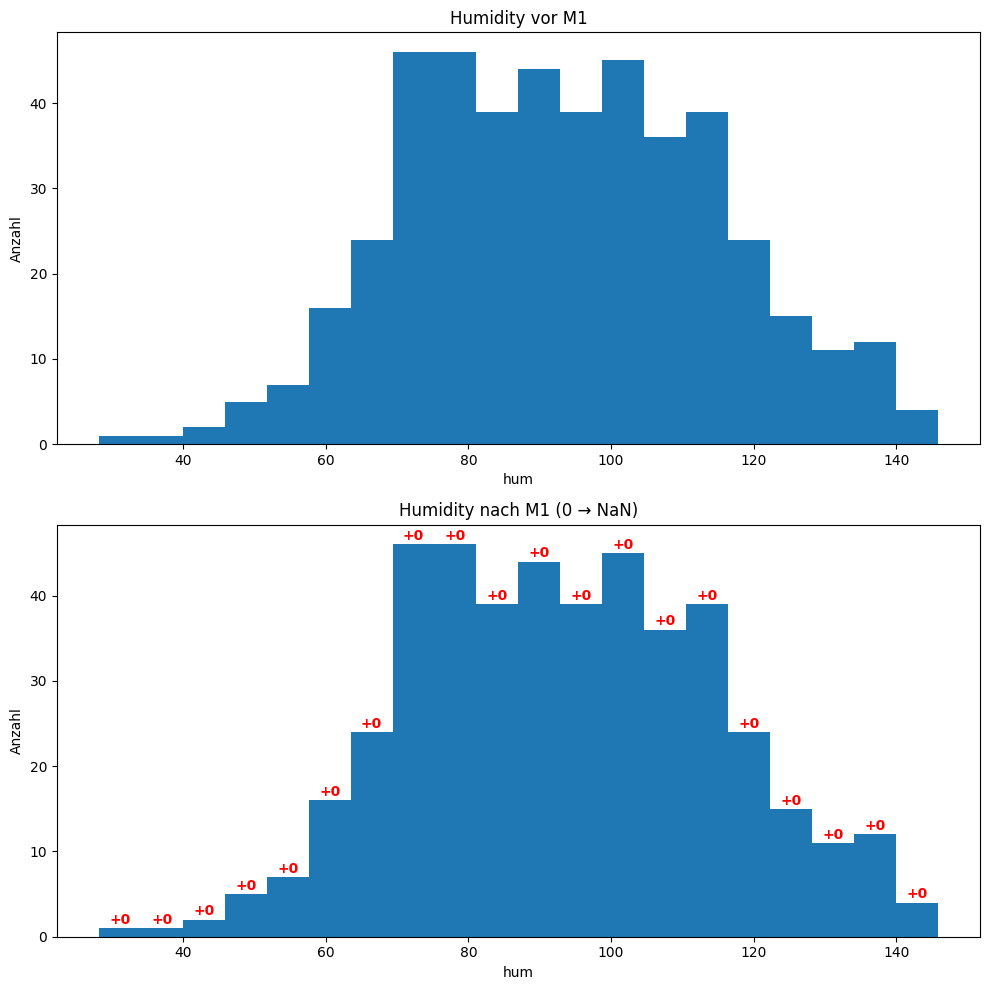

In [8]:
# M1: Humidity – Vorher vs. Nachher

plt.figure(figsize=(10, 10))

# Vorher
plt.subplot(2, 1, 1)
before_counts, bin_edges, _ = plt.hist(train_df["hum"].dropna(), bins=20)
plt.title("Humidity vor M1")
plt.xlabel("hum")
plt.ylabel("Anzahl")

print("Humidity VOR M1:")
print(train_df["hum"].describe())
print("0 Werte:", (train_df["hum"] == 0).sum())
print("NaN:", train_df["hum"].isna().sum())
print("--------------------------------------")

# Nachher

# Daten durch M1 schicken
train_M1 = rule_based(train_df) 

plt.subplot(2, 1, 2)
after_counts, _, _ = plt.hist(train_M1["hum"].dropna(), bins=bin_edges)
plt.title("Humidity nach M1 (0 → NaN)")
plt.xlabel("hum")
plt.ylabel("Anzahl")

print("Humidity NACH M1:")
print(train_M1["hum"].describe())
print("0 Werte:", (train_M1["hum"] == 0).sum())
print("NaN:", train_M1["hum"].isna().sum())
print("--------------------------------------")

# Differenzen über den Säulen

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

for x, before, after in zip(bin_centers, before_counts, after_counts):
    diff = int(after - before)
    plt.text(
        x,
        after + 0.5,   # knapp über der Säule
        f"{diff:+d}",
        ha="center",
        color="red",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


Windspeed VOR M1:
count    480.000000
mean       0.181481
std        0.133543
min       -1.000000
25%        0.133083
50%        0.181905
75%        0.233367
max        0.507463
Name: windspeed, dtype: float64
−1 Werte: 4
NaN: 0
--------------------------------------
Windspeed NACH M1:
count    476.000000
mean       0.191409
std        0.078296
min        0.022392
25%        0.134183
50%        0.183148
75%        0.233999
max        0.507463
Name: windspeed, dtype: float64
−1 Werte: 0
NaN: 4
--------------------------------------


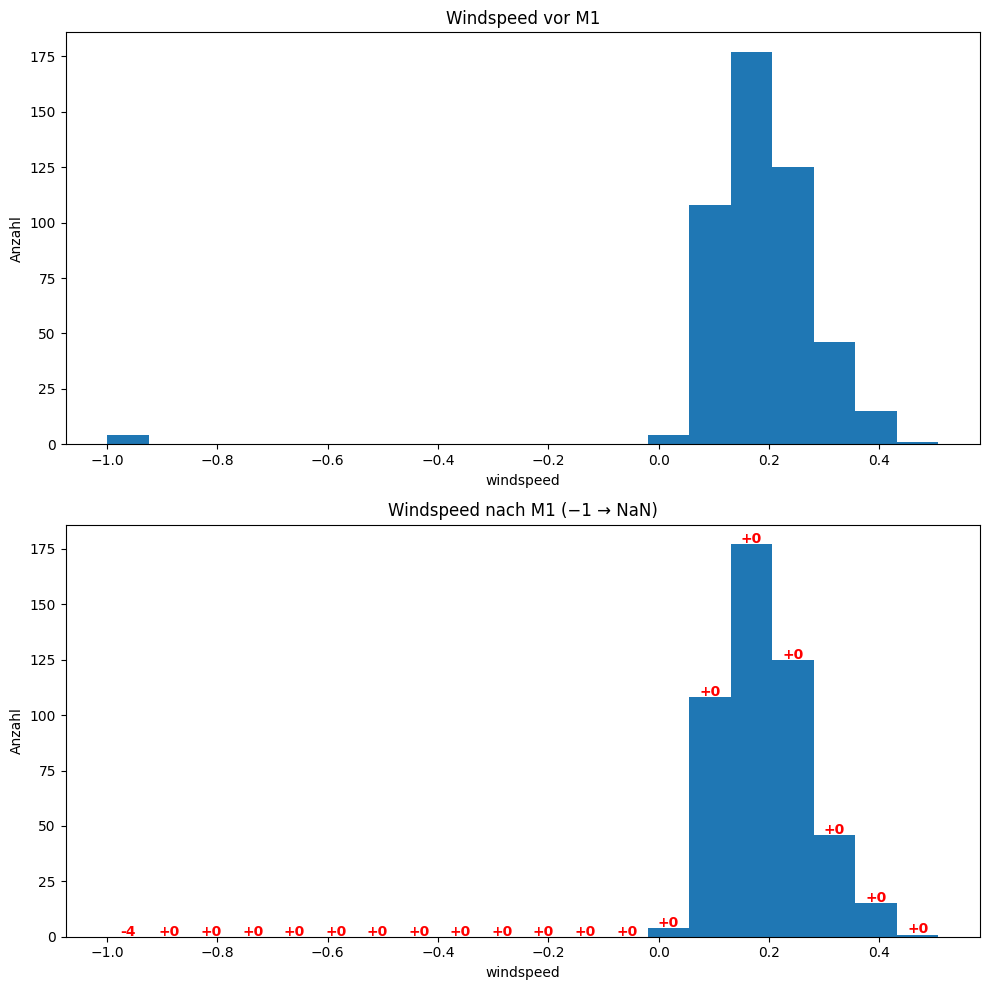

In [9]:
# M1: Windspeed – Vorher vs. Nachher (sichtbare Differenzen)

plt.figure(figsize=(10, 10))

# Vorher

plt.subplot(2, 1, 1)
before_counts, bin_edges, _ = plt.hist(train_df["windspeed"].dropna(), bins=20)
plt.title("Windspeed vor M1")
plt.xlabel("windspeed")
plt.ylabel("Anzahl")

print("Windspeed VOR M1:")
print(train_df["windspeed"].describe())
print("−1 Werte:", (train_df["windspeed"] == -1).sum())
print("NaN:", train_df["windspeed"].isna().sum())
print("--------------------------------------")

# Nachher

# Daten durch M1 schicken
train_M1 = rule_based(train_df)

plt.subplot(2, 1, 2)
after_counts, _, _ = plt.hist(train_M1["windspeed"].dropna(), bins=bin_edges)
plt.title("Windspeed nach M1 (−1 → NaN)")
plt.xlabel("windspeed")
plt.ylabel("Anzahl")

print("Windspeed NACH M1:")
print(train_M1["windspeed"].describe())
print("−1 Werte:", (train_M1["windspeed"] == -1).sum())
print("NaN:", train_M1["windspeed"].isna().sum())
print("--------------------------------------")

# Differenzen über den Säulen

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

for x, before, after in zip(bin_centers, before_counts, after_counts):
    diff = int(after - before)
    plt.text(
        x,
        after + 0.5,
        f"{diff:+d}",
        ha="center",
        color="red",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

Season VOR M1:
season
1.0    110
2.0    115
3.0    114
4.0     95
NaN     46
Name: count, dtype: int64
--------------------------------
Season NACH M1:
season
1    115
2    118
3    121
4    126
Name: count, dtype: int64
--------------------------------


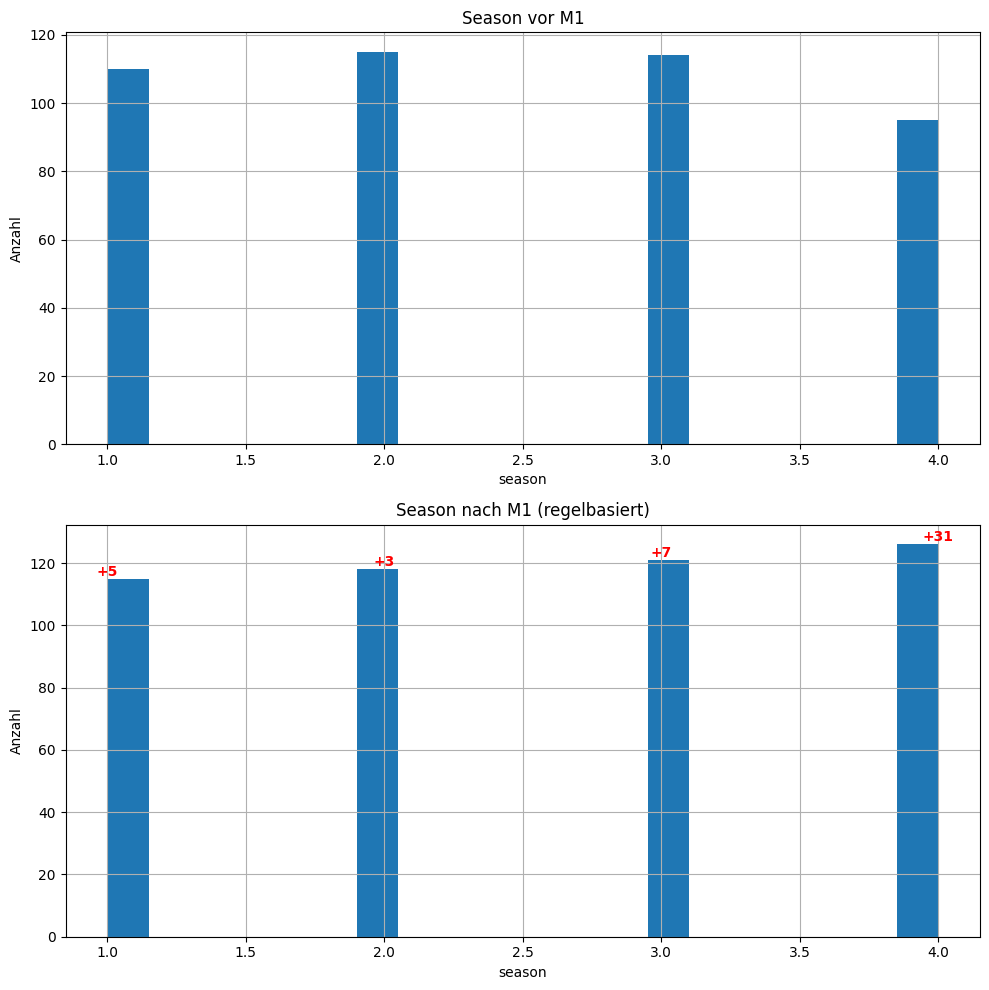

In [10]:
# M1: Season – Vorher vs. Nachher 

plt.figure(figsize=(10, 10))

# Vorher
plt.subplot(2, 1, 1)
hist = train_df["season"].hist(bins=20)
before_counts = train_df["season"].value_counts(dropna=False).sort_index()

plt.title("Season vor M1")
plt.xlabel("season")
plt.ylabel("Anzahl")

print("Season VOR M1:")
print(before_counts)
print("--------------------------------")

# Nachher
plt.subplot(2, 1, 2)
hist = train_M1["season"].hist(bins=20)
after_counts = train_M1["season"].value_counts(dropna=False).sort_index()

plt.title("Season nach M1 (regelbasiert)")
plt.xlabel("season")
plt.ylabel("Anzahl")

print("Season NACH M1:")
print(after_counts)
print("--------------------------------")

# Differenzen über den Säulen
for s in after_counts.index:
    diff = after_counts.get(s, 0) - before_counts.get(s, 0)
    plt.text(
        s,
        after_counts[s] + 1,
        f"{diff:+d}",
        color="red",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

M1 – weekday vor der Transformation:
weekday
-1    15
 0    65
 1    70
 2    61
 3    63
 4    67
 5    69
 6    70
Name: count, dtype: int64
------------------------------------
M1 – weekday nach der Transformation:
weekday
0    72
1    62
2    65
3    70
4    70
5    72
6    69
Name: count, dtype: int64
------------------------------------


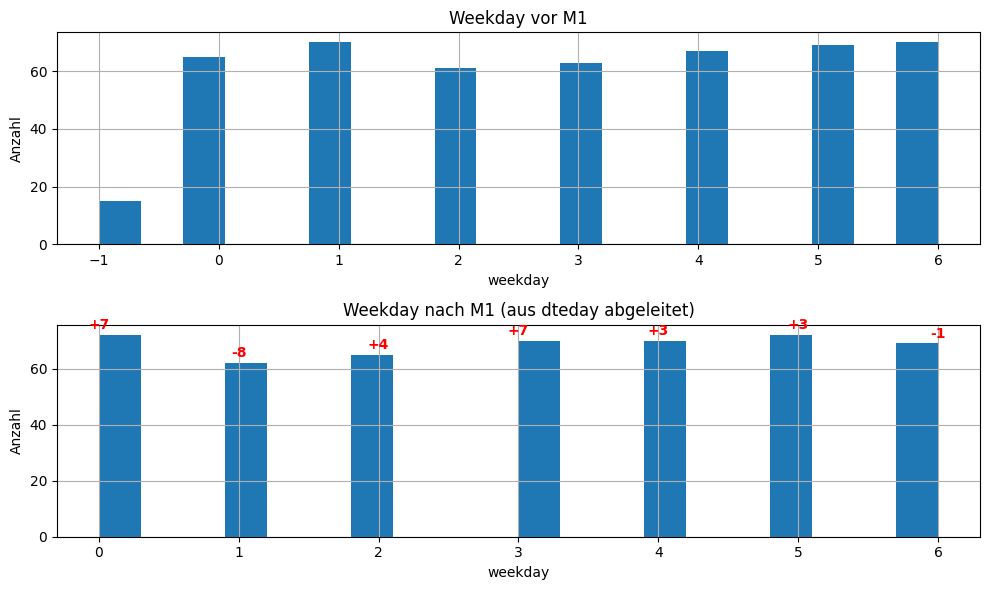

In [11]:
# M1: weekday Ableitung aus Datum Vorher vs. Nachher

plt.figure(figsize=(10, 6))

# Vorher
plt.subplot(2, 1, 1)
hist = train_df["weekday"].hist(bins=20)
counts_before = train_df["weekday"].value_counts(dropna=False).sort_index()
plt.title("Weekday vor M1")
plt.xlabel("weekday")
plt.ylabel("Anzahl")
print("M1 – weekday vor der Transformation:")
print(counts_before)
print("------------------------------------")

# Nachher
plt.subplot(2, 1, 2)
hist = train_M1["weekday"].hist(bins=20)
counts_after = train_M1["weekday"].value_counts(dropna=False).sort_index()
plt.title("Weekday nach M1 (aus dteday abgeleitet)")
plt.xlabel("weekday")
plt.ylabel("Anzahl")
print("M1 – weekday nach der Transformation:")
print(counts_after)
print("------------------------------------")

# Differenzen über den Säulen
for weekday_value in counts_after.index:
    before_val = counts_before.get(weekday_value, 0)
    after_val = counts_after.get(weekday_value, 0)
    diff = after_val - before_val

    # Position über dem Balken schätzen
    plt.text(
        weekday_value,              # X-Position = Wochentag
        after_val + 1,               # Y-Position etwas über dem Balken
        f"{diff:+d}",                # zeigt +12 oder -3
        ha='center',
        va='bottom',
        color='red',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

### M2: Missing Value Handling

hier werden die NaN-Werte statistisch korrekt behandelt. Durch imput des Median werden robuste Schätzungen erfasst, wodurch Verzerrungen reduziert werden. 

In [12]:
def missing_value(df):

    df = df.copy()

    # Windspeed fixen
    # Median der gültigen Windgeschwindigkeiten berechnen (Median ist robust gegenübern Ausreißern)
    windspeed = df["windspeed"].median()  

    # NaN durch Median ersetzen
    df["windspeed"] = df["windspeed"].fillna(windspeed) 


    # Hum fixen
    # Wetterlagen durch Mediane erfassen
    weather_hum_median = df.groupby("weathersit")["hum"].median() 


    # Methode zum Mapping der fehlenden Humidity Werte
    def hum_nan_fix(row):

        # Prüfen, ob Humidity in dieser Zeile fehlt und dann Fehlerwert mit weathersit-Median ersetzen
        if pd.isna(row["hum"]):
            return weather_hum_median[row["weathersit"]]
        
        # Ansonsten unverändert lassen
        else:
            return row["hum"]  

    # Anwenden der Methode hum_nan_fix auf jede Zeile
    df["hum"] = df.apply(hum_nan_fix, axis=1)

    return df


M2 – hum vor der Imputation:
  NaN: 24
------------------------------------
M2 – hum nach der Imputation:
  NaN: 0
------------------------------------


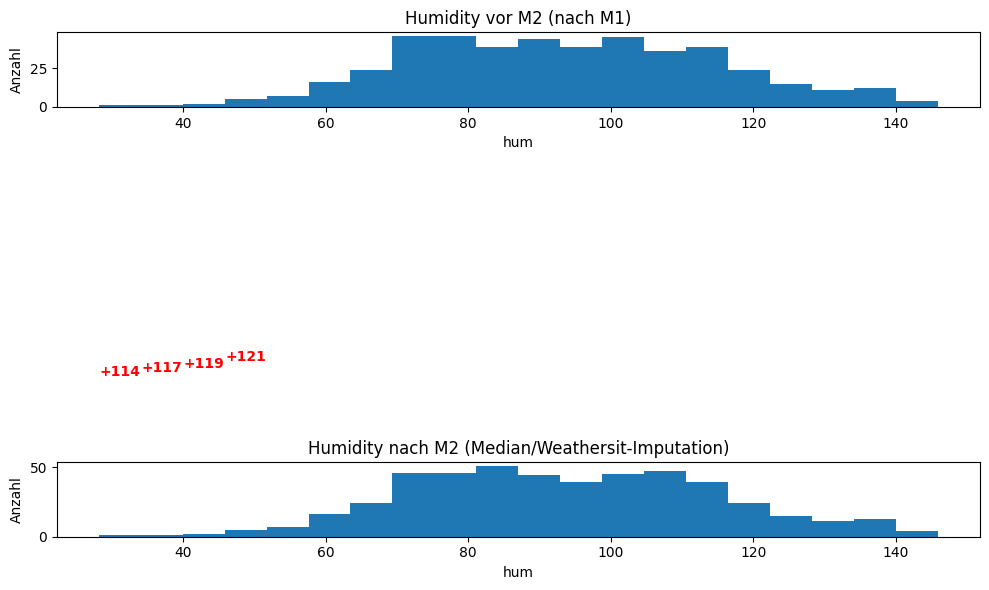

In [13]:
# M2: Missing Value Handling – hum Vorher vs Nachher

plt.figure(figsize=(10, 6))

# Histogramm-Bins für beide Plots identisch halten
before_counts, bin_edges = np.histogram(train_M1["hum"].dropna(), bins=20)

# Vorher
plt.subplot(2, 1, 1)
plt.hist(train_M1["hum"].dropna(), bins=bin_edges)
mv_before = train_M1["hum"].isna().sum()
plt.title("Humidity vor M2 (nach M1)")
plt.xlabel("hum")
plt.ylabel("Anzahl")
print("M2 – hum vor der Imputation:")
print(f"  NaN: {mv_before}")
print("------------------------------------")

# Nachher
# Daten durch M2 schicken
train_M2 = missing_value(train_M1)

plt.subplot(2, 1, 2)
plt.hist(train_M2["hum"].dropna(), bins=bin_edges)
mv_after = train_M2["hum"].isna().sum()
plt.title("Humidity nach M2 (Median/Weathersit-Imputation)")
plt.xlabel("hum")
plt.ylabel("Anzahl")
print("M2 – hum nach der Imputation:")
print(f"  NaN: {mv_after}")
print("------------------------------------")

# Differenz
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

for x, before, after in zip(bin_centers, before_counts, after_counts):
    diff = int(after - before)
    plt.text(x, after + 0.5, f"{diff:+d}", ha="center", color="red", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

Windspeed VOR M2:
count    476.000000
mean       0.191409
std        0.078296
min        0.022392
25%        0.134183
50%        0.183148
75%        0.233999
max        0.507463
Name: windspeed, dtype: float64
NaN: 4
--------------------------------------
Windspeed NACH M2:
count    480.000000
mean       0.191340
std        0.077972
min        0.022392
25%        0.134797
50%        0.183148
75%        0.233367
max        0.507463
Name: windspeed, dtype: float64
NaN: 0
--------------------------------------


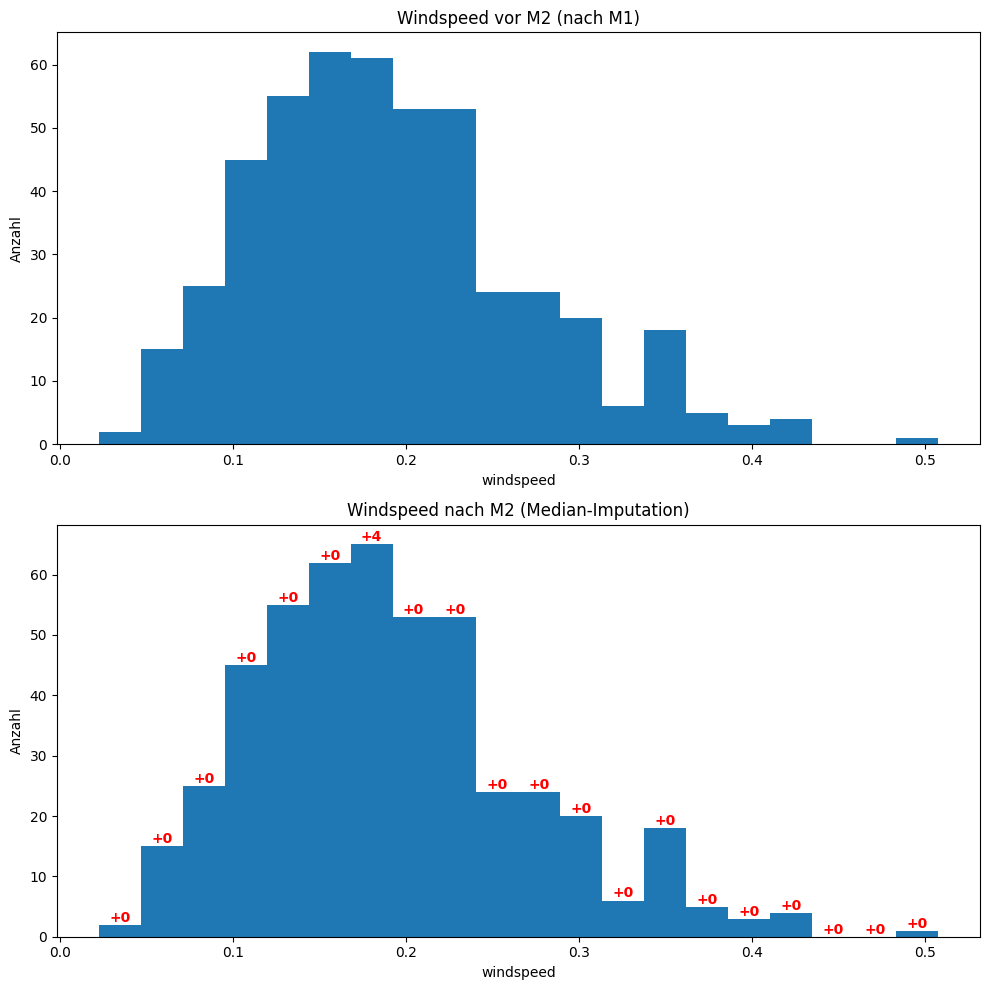

In [14]:
# M2: Windspeed | Vorher vs. Nachher 

plt.figure(figsize=(10, 10))

# Vorher
plt.subplot(2, 1, 1)
before_counts, bin_edges, _ = plt.hist(train_M1["windspeed"].dropna(), bins=20)
plt.title("Windspeed vor M2 (nach M1)")
plt.xlabel("windspeed")
plt.ylabel("Anzahl")

print("Windspeed VOR M2:")
print(train_M1["windspeed"].describe())
print("NaN:", train_M1["windspeed"].isna().sum())
print("--------------------------------------")

# Nacher

# Daten durch M2 schicken
train_M2 = missing_value(train_M1)

plt.subplot(2, 1, 2)
after_counts, _, _ = plt.hist(train_M2["windspeed"].dropna(), bins=bin_edges)
plt.title("Windspeed nach M2 (Median-Imputation)")
plt.xlabel("windspeed")
plt.ylabel("Anzahl")

print("Windspeed NACH M2:")
print(train_M2["windspeed"].describe())
print("NaN:", train_M2["windspeed"].isna().sum())
print("--------------------------------------")

# Differenzen über den Säulen
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

for x, before, after in zip(bin_centers, before_counts, after_counts):
    diff = int(after - before)
    plt.text(x, after + 0.5, f"{diff:+d}", ha="center", color="red", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


### M3: Feature Removal

In diesem Schritt werden Variablen entfernt, die für das Modell entweder keine zusätzlichen Informationen liefern, redundant sind oder die Vorhersagequalität künstlich verzerren würden. Die beiden Spalten casual und registered enthalten bereits direkte Bestandteile der Zielgröße cnt und würden dadurch zu einer unerlaubten Informationsweitergabe führen, weshalb sie ausgeschlossen werden. Die Variable price reduction ist nicht in allen Beobachtungen konsistent vorhanden und wird daher ebenfalls entfernt. Zudem entfällt temp, da sie stark mit atemp korreliert und somit keine eigenständige Aussagekraft besitzt. Auch die Attribute holiday, mnth und dteday werden entfernt, da ihre Information entweder bereits in anderen Features enthalten ist oder für das Modell keinen zusätzlichen Nutzen bietet.
Durch diesen Schritt stellt man sicher, dass das modell robuster gegenüber Verzerrungen wird und verbessert seine Fähigkeit neue Daten zu generalisieren.

In [15]:
# Feature Removal Funktion
def feature_removal(df):

    df = df.copy()

    # Liste aller Spalten, die Leakage erzeugen oder redundant sind
    drop_list = [

        "casual",
        "registered",
        "temp",
        "mnth",
        "holiday",
        "price reduction",
        "dteday"
    ] 

    # Entfernen von den obengennanten Spalten
    df = df.drop(columns=drop_list, errors='ignore') 

    return df


In [16]:
# M3: Darstellung der entfernten Features | Vorher vs. Nachher

# Daten durch M3 schicken
train_M3 = feature_removal(train_M2)

# Features, die in M3 entfernt werden + Begründung
removed_features = {
    "casual": "Teil der Zielvariable (leaking)",
    "registered": "Teil der Zielvariable (leaking)",
    "temp": "hoch korreliert mit atemp (Redundanz)",
    "holiday": "geringe Varianz, wenig Einfluss",
    "mnth": "redundant (ersetzt durch season/weekday)",
    "price reduction": "inkonsistente Werte / unvollständig",
    "dteday": "redundant (Datum bereits in weekday/season verarbeitet)"
}

# Überblick in Tabelle
df_removed = pd.DataFrame({
    "Feature": removed_features.keys(),
    "Vor M3 vorhanden?": ["ja"] * len(removed_features),
    "Nach M3 vorhanden?": ["nein"] * len(removed_features),
    "Grund": removed_features.values()
})

display(df_removed)

# Automatischer Vergleich zur Kontrolle
print("--------------------------------------------------")
print("Features vor M3:", len(train_M2.columns))
print("Features nach M3:", len(train_M3.columns))
print("Entfernt wurden:", set(train_M2.columns) - set(train_M3.columns))
print("--------------------------------------------------")


,Feature,Vor M3 vorhanden?,Nach M3 vorhanden?,Grund
0,casual,ja,nein,Teil der Zielvariable (leaking)
1,registered,ja,nein,Teil der Zielvariable (leaking)
2,temp,ja,nein,hoch korreliert mit atemp (Redundanz)
3,holiday,ja,nein,"geringe Varianz, wenig Einfluss"
4,mnth,ja,nein,redundant (ersetzt durch season/weekday)
5,price reduction,ja,nein,inkonsistente Werte / unvollständig
6,dteday,ja,nein,redundant (Datum bereits in weekday/season ver...


--------------------------------------------------
Features vor M3: 17
Features nach M3: 11
Entfernt wurden: {'mnth', 'registered', 'price reduction', 'holiday', 'temp', 'casual'}
--------------------------------------------------


### M4: One Hot Encoding

Hier werden die kategorialen Variablen so umgewandelt, dass sie von den Modellen korrekt verarbeitet werden können. Da Algorithmen wie die lineare Regression nur numerische Werte verarbeiten, werden Kategorien wie season, weathersit und weekday mithilfe des One-Hot-Encodings in mehrere Dummy-Variablen aufgeteilt. Dabei wird jeweils eine Referenzkategorie weggelassen, um unnötige Abhängigkeiten zwischen den erzeugten Spalten zu vermeiden.

In [17]:
# One-Hot-Encoding

def one_hot_and_align(train_df, other_df, categories = None):

    # Features die kategorisiert werden sollten
    categories = ["season", "weathersit", "weekday"]

    # Kopien
    train_df = train_df.copy()   # Trainingskopie: liefert Referenzlayout und Dummy-Spalten
    other_df = other_df.copy()   # "other" steht für Val/Test und soll später an Train angeglichen werden


    # 1) One-Hot-Encoding auf beiden DataFrames
    # drop_first = True damit Multikolinearität vermieden werden kann
    train_df = pd.get_dummies(train_df, columns=categories, drop_first=True)  
    other_df = pd.get_dummies(other_df, columns=categories, drop_first=True)

    # 2) Fehlende Spalten die im Training auftuachen aber nicht in der Validierung/ Test dann mit dem Wert 0 im other_df_copy auffüllen
    # Herausfinden, welche Spalten die train_df_copy besitzt, other_df_copy aber nicht
    missed_columns = set(train_df.columns) - set(other_df.columns)  

    #In einer Schleife alle fehlenden Dummies als 0 hinzufügen, damit die Modelle dieselbe Form erhalten
    for columns in missed_columns:
        other_df[columns] = 0 

    # 2) Fehlende Spalten die im Validierungs/ Testdatensatz auftauchen aber nicht im Trainingsdatensatz entfernen
    # Herausfinden, welche Spalten die other_df_copy besitzt, train_df_copy aber nicht
    extra_cols_in_other = set(other_df.columns) - set(train_df.columns) 

    #In einer Schleife alle fehlenden Dummies als 0 hinzufügen, damit die Modelle dieselbe Form erhalten
    if extra_cols_in_other:
        other_df = other_df.drop(columns=list(extra_cols_in_other)) 

    # 4) Spalten sortieren um Reihenfolge von Train und Val/ Test anzugleichen
    # OHE angewendeter Datensatz (train_df_copy) nach Spaltennamen sortieren
    train_df = train_df.sort_index(axis=1)        

    # Spaltenriehenfolge von other_df_copy (also val/ test) an train_df_copy angleichen
    other_df = other_df[train_df.columns]

    return train_df, other_df


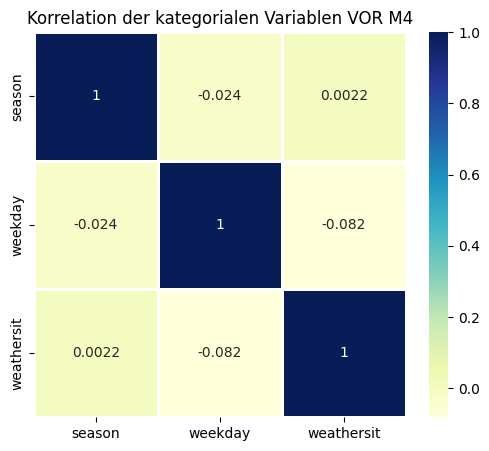

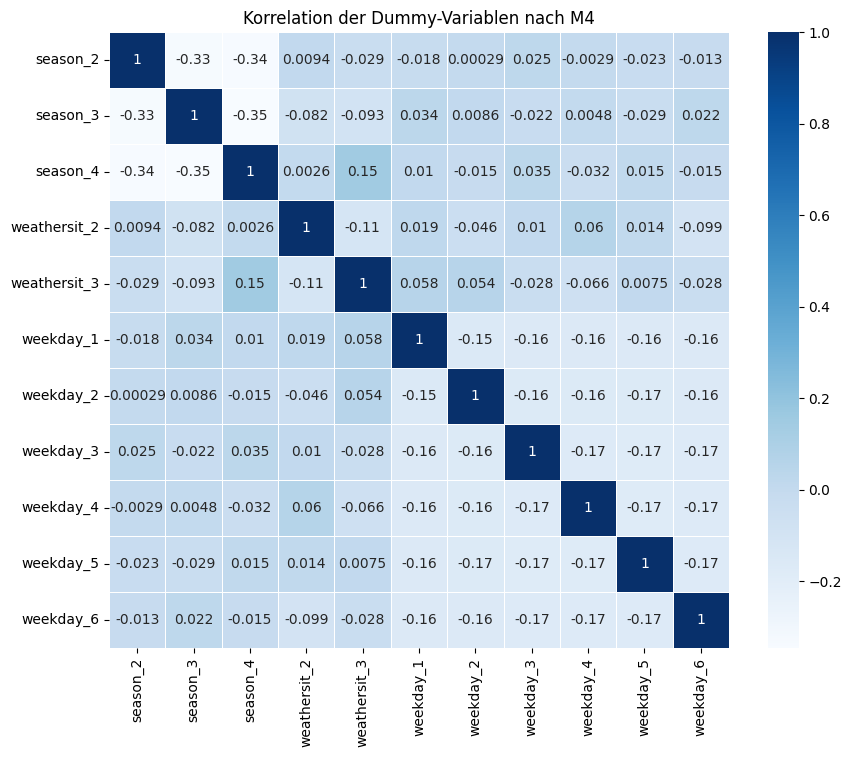

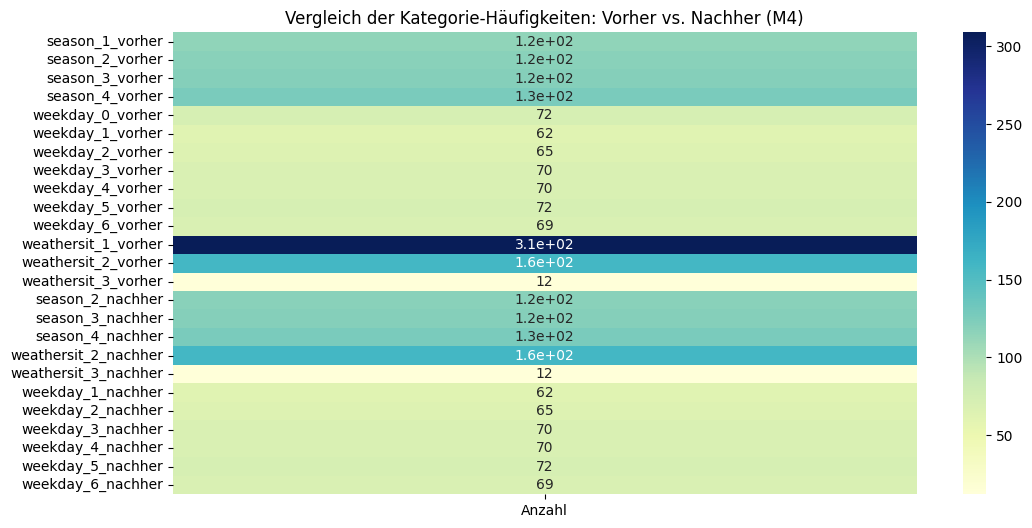

In [18]:
# M4 – One-Hot-Encoding Heatmaps

# Kategorien VOR One-Hot-Encoding
categorical_before = ["season", "weekday", "weathersit"]

# Korrelation der rohen Kategorien
plt.figure(figsize=(6,5))
sns.heatmap(train_M3[categorical_before].corr(), annot=True, cmap="YlGnBu", linewidths=1)
plt.title("Korrelation der kategorialen Variablen VOR M4")
plt.show()

# Daten durch M4 schicken
train_M4, val_M4 = one_hot_and_align(train_M3, val_df)

# Heatmap | Dummy-Korrelationen nach M4
# Alle Dummy-Spalten finden
dummy_cols = [col for col in train_M4.columns if "_" in col and col.split("_")[0] in ["season", "weekday", "weathersit"]]

plt.figure(figsize=(10, 8))
sns.heatmap(train_M4[dummy_cols].corr(), annot=True, cmap="Blues", linewidths=.5)
plt.title("Korrelation der Dummy-Variablen nach M4")
plt.show()


# HEATMAP – Kategorie-Frequenzen vor/nach M4

freq_data = {}

# Vorher-Häufigkeiten (train_M3)
for feature in ["season", "weekday", "weathersit"]:
    if feature in train_M3.columns:
        counts_before = train_M3[feature].value_counts().sort_index()
        for cat, val in counts_before.items():
            freq_data[f"{feature}_{cat}_vorher"] = val

# Nachher-Häufigkeiten (Dummy-Summen)
for col in dummy_cols:
    freq_data[f"{col}_nachher"] = train_M4[col].sum()

# In DataFrame umwandeln für Heatmap
freq_df = pd.DataFrame(freq_data, index=["Anzahl"]).T

plt.figure(figsize=(12, 6))
sns.heatmap(freq_df, annot=True, cmap="YlGnBu")
plt.title("Vergleich der Kategorie-Häufigkeiten: Vorher vs. Nachher (M4)")
plt.show()


### M5 Scaling

Zum Abschluss der Datenvorbereitung werden ausgewählte numerische Variablen standardisiert, um sie auf einen gemeinsamen Wertebereich zu bringen. Die Merkmale instant, atemp, hum und windspeed unterscheiden sich stark in ihrer Skalierung, was insbesondere lineare Modelle in ihrer Leistungsfähigkeit beeinträchtigen kann. Durch die Z-Standardisierung werden sie in eine Form gebracht, bei der sie einen Mittelwert von 0 und eine Standardabweichung von 1 besitzen.
Dabei wird der Skalierungsparameter ausschließlich auf den Trainingsdaten berechnet, um eine unbeabsichtigte Informationsübertragung in die Validierungs- und Testdaten zu vermeiden. Anschließend wird dieselbe Transformation auf die übrigen Datensätze angewendet.
Durch die Vereinheitlichung der Skalen können Modelle schneller und zuverlässiger lernen, und die Bedeutung einzelner Merkmale wird besser vergleichbar.

In [19]:
# Liste der numerischen Features, die wirklich skaliert werden sollen:
to_scale = ["instant", "atemp", "hum", "windspeed"]

def scale_train(df):
    df = df.copy()

    # Scaler initialisieren
    scaler = StandardScaler()

    # Fit + Transform auf Trainingsdaten
    df[to_scale] = scaler.fit_transform(df[to_scale])

    return df, scaler

def scale_apply(df, scaler):
    df = df.copy()

    # Transform auf Validation/Test anwenden
    df[to_scale] = scaler.transform(df[to_scale])

    return df

log_results = {}

M5 – instant:
  Vor M5: count    480.000000
mean     363.879167
std      208.216580
min        2.000000
25%      184.750000
50%      359.500000
75%      538.250000
max      731.000000
Name: instant, dtype: float64
  Nach M5: count    4.800000e+02
mean     2.220446e-17
std      1.001043e+00
min     -1.739807e+00
25%     -8.611997e-01
50%     -2.105373e-02
75%      8.383230e-01
max      1.765008e+00
Name: instant, dtype: float64
------------------------------------


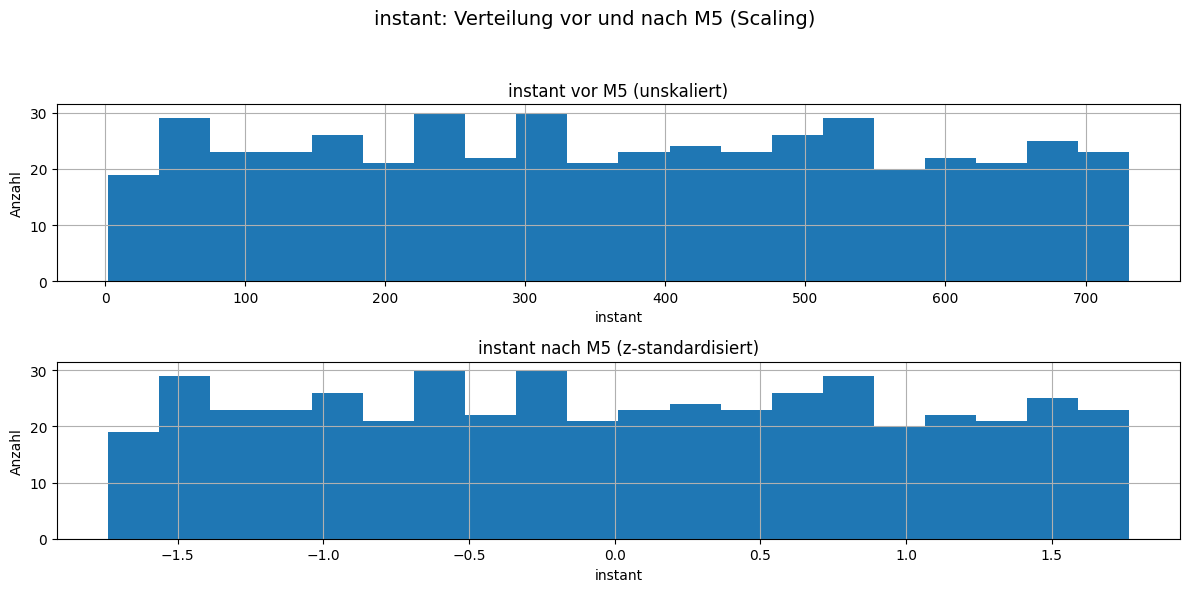

M5 – atemp:
  Vor M5: count    480.000000
mean       0.474369
std        0.160269
min        0.079070
25%        0.331115
50%        0.495258
75%        0.607965
max        0.826371
Name: atemp, dtype: float64
  Nach M5: count    4.800000e+02
mean     2.072416e-16
std      1.001043e+00
min     -2.469042e+00
25%     -8.947619e-01
50%      1.304787e-01
75%      8.344463e-01
max      2.198611e+00
Name: atemp, dtype: float64
------------------------------------


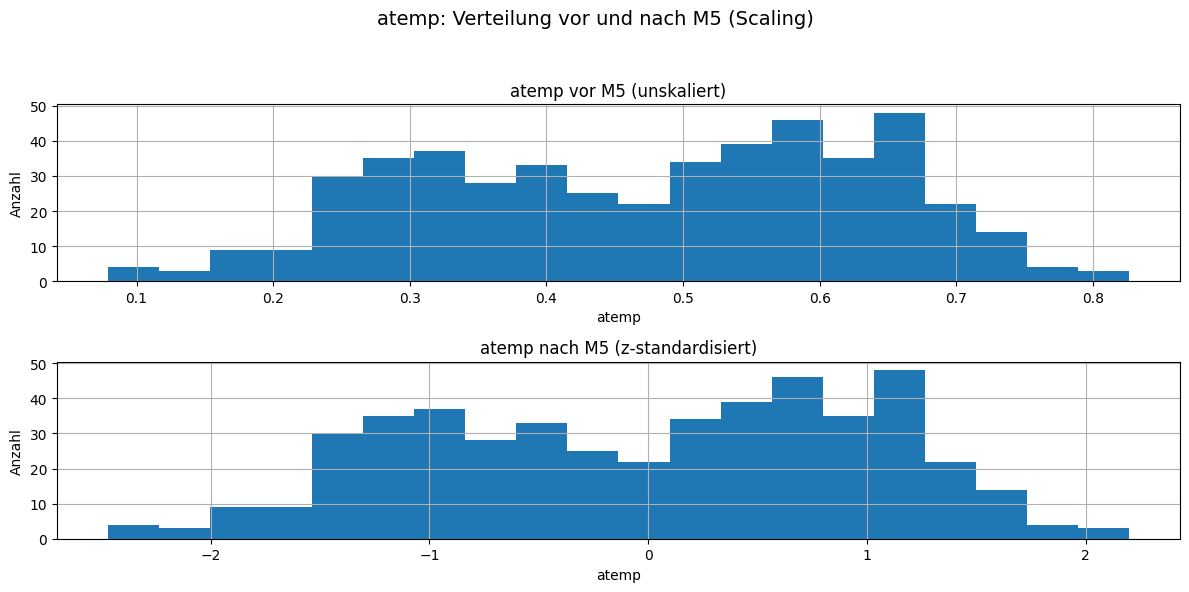

M5 – hum:
  Vor M5: count    480.000000
mean      93.495332
std       21.252918
min       28.187550
25%       77.234400
50%       92.334300
75%      110.132850
max      145.875000
Name: hum, dtype: float64
  Nach M5: count    4.800000e+02
mean     4.810966e-17
std      1.001043e+00
min     -3.076091e+00
25%     -7.659135e-01
50%     -5.468627e-02
75%      7.836513e-01
max      2.467158e+00
Name: hum, dtype: float64
------------------------------------


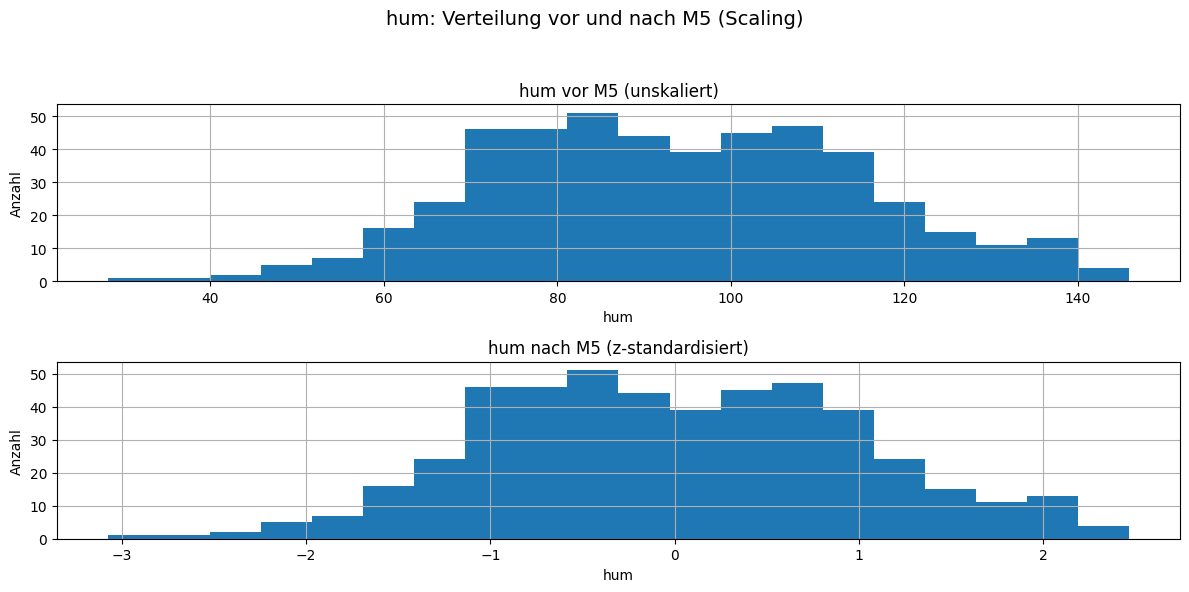

M5 – windspeed:
  Vor M5: count    480.000000
mean       0.191340
std        0.077972
min        0.022392
25%        0.134797
50%        0.183148
75%        0.233367
max        0.507463
Name: windspeed, dtype: float64
  Nach M5: count    4.800000e+02
mean    -1.480297e-17
std      1.001043e+00
min     -2.169048e+00
25%     -7.259350e-01
50%     -1.051770e-01
75%      5.395537e-01
max      4.058544e+00
Name: windspeed, dtype: float64
------------------------------------


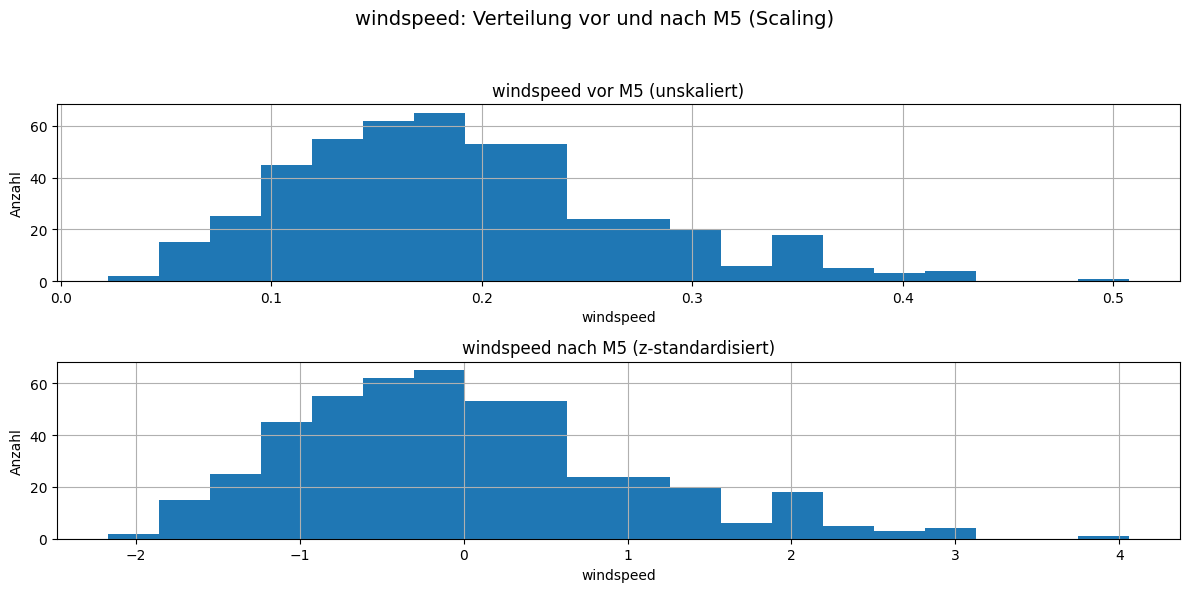

In [20]:
# M5: Scaling Vorher vs. Nachher

# Daten durch M5 schicken
train_M5_scaled, scaler = scale_train(train_M4)
val_M5_scaled = scale_apply(val_M4, scaler)

scaled_features = ["instant", "atemp", "hum", "windspeed"]

for feature in scaled_features:
    plt.figure(figsize=(12, 6))
    plt.suptitle(f"{feature}: Verteilung vor und nach M5 (Scaling)", fontsize=14)
    
    # Vorher (M4 – unskaliert)
    plt.subplot(2, 1, 1)
    hist = train_M4[feature].hist(bins=20)
    plt.title(f"{feature} vor M5 (unskaliert)")
    plt.xlabel(feature)
    plt.ylabel("Anzahl")
    
    # Nachher (M5 – z-skaliert)
    plt.subplot(2, 1, 2)
    hist = train_M5_scaled[feature].hist(bins=20)
    plt.title(f"{feature} nach M5 (z-standardisiert)")
    plt.xlabel(feature)
    plt.ylabel("Anzahl")
    
    print(f"M5 – {feature}:")
    print("  Vor M5:", train_M4[feature].describe())
    print("  Nach M5:", train_M5_scaled[feature].describe())
    print("------------------------------------")
    
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


### Baseline erstellen
Die Baseline ist unser Startpunkt, um zu sehen, wie gut ein sehr einfaches Modell ohne großes Preprocessing funktioniert. Dafür nehmen wir nur ein paar ursprüngliche Features (instant, yr, workingday) und trainieren darauf eine lineare Regression.
So bekommen wir einen Vergleichswert: Alles, was wir später durch Preprocessing und Feature-Engineering verbessern, sollte deutlich besser sein als diese einfache Baseline.

In [21]:

# Zielvariable definieren
target = "cnt"

# Minimaler Feature-Satz als Referenz (keine transformierten Features)
baseline_features = ["instant", "yr", "workingday"]

# Trainings- und Validierungsdaten vorbereiten
# Feature-Matrizen
X_train_base = train_df[baseline_features].copy()
X_val_base   = val_df[baseline_features].copy()

# Zielvariablen
y_train_base = train_df[target].copy()
y_val_base   = val_df[target].copy()

# Fehlende Werte behandeln
# Nur Mittelwert-Imputation des TRAINING-Sets zur Vermeidung von Data Leakage

X_train_base = X_train_base.fillna(X_train_base.mean())
X_val_base   = X_val_base.fillna(X_train_base.mean())

# Baseline-Modell erstellen & trainieren

baseline_model = LinearRegression()
baseline_model.fit(X_train_base, y_train_base)

# Vorhersagen auf dem Validierungsdatensatz

baseline_pred = baseline_model.predict(X_val_base)

# Metriken berechnen (MAE & R²)
baseline_mae = mean_absolute_error(y_val_base, baseline_pred)
baseline_r2  = r2_score(y_val_base, baseline_pred)


# Ergebnisse ausgeben

print("Baseline Evaluation")
print("MAE:", baseline_mae)
print("R² :", baseline_r2)


# Ergebnisse im Log speichern

log_results["baseline"] = {
    "MAE": baseline_mae,
    "R2": baseline_r2
}

Baseline Evaluation
MAE: 1728.2219388325873
R² : 0.11388378988858128


### Preprocessing & Training von M1-M5

Nach der Baseline wird der vollständige Preprocessing-Workflow angewendet, der aus den Modulen M1 bis M5 besteht. Jede Stufe erweitert oder bereinigt die Daten systematisch und bereitet sie optimal für die Modellierung vor.
Sobald alle Schritte durchgeführt wurden, werden die erzeugten Features in Trainings- und Validierungsdaten getrennt und dem Modell als Eingabe bereitgestellt. Die Funktion train_and_evaluate() übernimmt dabei das Trainieren der linearen Regression und die anschließende Bewertung mithilfe von MAE und R².
Durch dieses konsistente Vorgehen lässt sich genau nachvollziehen, wie sich jede Stufe der Datenaufbereitung auf die Modellleistung auswirkt. So kann die gesamte Pipeline iterativ verbessert und transparent dokumentiert werden.

In [22]:
def train_and_evaluate(X_train, y_train, X_val, y_val, name, log_dict):
    # Modell initialisieren und trainieren
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Vorhersage auf Validation
    y_pred = model.predict(X_val)

    # Kennzahlen
    mae = mean_absolute_error(y_val, y_pred)
    r2  = r2_score(y_val, y_pred)

    # Ausgabe
    print(f"Evaluation von {name}")
    print("MAE:", mae)
    print("R² :", r2)
    print()

    # Loggen
    log_dict[name] = {"MAE": mae, "R2": r2}

    return model

In [23]:
#M1
# Initiierung von Trainings und Validierungsdaten
train_M1 = rule_based(train_df)  
val_M1   = rule_based(val_df)    

# NaN-Check Trainingsdaten
print("M1 – NaN-Check (Train):")
print(train_M1.isna().sum())

# NaN-Checl Validierungsdaten
print("\nM1 – NaN-Check (Val):")
print(val_M1.isna().sum())

M1 – NaN-Check (Train):
instant             0
season              0
yr                  0
mnth                0
holiday             0
weekday             0
workingday          0
weathersit          0
temp                0
atemp               0
hum                24
windspeed           4
leaflets            0
price reduction     0
casual              0
registered          0
cnt                 0
dtype: int64

M1 – NaN-Check (Val):
instant             0
season              0
yr                  0
mnth                0
holiday             0
weekday             0
workingday          0
weathersit          0
temp                0
atemp               0
hum                10
windspeed           0
leaflets            0
price reduction     0
casual              0
registered          0
cnt                 0
dtype: int64


In [24]:

#M2
# Initiierung von Trainings und Validierungsdaten
train_M2 = missing_value(train_M1)
val_M2   = missing_value(val_M1)

# NaN-Check Trainingsdaten
print("M2 – NaN-Check (Train):")
print(train_M2.isna().sum())

# NaN-Check Validierungsdaten
print("\nM2 – NaN-Check (Val):")
print(val_M2.isna().sum())

M2 – NaN-Check (Train):
instant            0
season             0
yr                 0
mnth               0
holiday            0
weekday            0
workingday         0
weathersit         0
temp               0
atemp              0
hum                0
windspeed          0
leaflets           0
price reduction    0
casual             0
registered         0
cnt                0
dtype: int64

M2 – NaN-Check (Val):
instant            0
season             0
yr                 0
mnth               0
holiday            0
weekday            0
workingday         0
weathersit         0
temp               0
atemp              0
hum                0
windspeed          0
leaflets           0
price reduction    0
casual             0
registered         0
cnt                0
dtype: int64


In [25]:
#M3: Feature Removal

# Initiierung von Trainings und Validierungsdaten
train_M3 = feature_removal(train_M2)
val_M3   = feature_removal(val_M2)

# Features extrahieren
features_M3 = [col for col in train_M3.columns if col != "cnt"]

# M3 evaluieren
train_and_evaluate(
    train_M3[features_M3], train_M3["cnt"],
    val_M3[features_M3],   val_M3["cnt"],
    "M3_feature_removal",
    log_results
)

Evaluation von M3_feature_removal
MAE: 1253.7161797907902
R² : 0.20468820061388293



,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [26]:
#M4: One-Hot-Encoding

# Initiierung von Trainings und Validierungsdaten
train_M4, val_M4_aligned = one_hot_and_align(
    train_M3,
    val_M3,
    categories=["season", "weathersit", "weekday"]
)

# Features extrahieren
features_M4 = [col for col in train_M4.columns if col != "cnt"]  # Alle numerischen + Dummy-Features (Target ausgeschlossen)

# M4 evaluieren
train_and_evaluate(
    train_M4[features_M4], train_M4["cnt"],
    val_M4_aligned[features_M4], val_M4_aligned["cnt"],
    "M4_one_hot",
    log_results,
)

Evaluation von M4_one_hot
MAE: 1284.4392282706824
R² : 0.24507759733117607



,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
# M5:

# Initiierung von Trainings und Validierungsdaten
train_M5_scaled, scaler = scale_train(train_M4)
val_M5_scaled           = scale_apply(val_M4_aligned, scaler)

# Features für M5
features_M5 = [col for col in train_M5_scaled.columns if col != "cnt"]

# M5 evaluieren
train_and_evaluate(
    train_M5_scaled[features_M5], train_M5_scaled["cnt"],
    val_M5_scaled[features_M5],   val_M5_scaled["cnt"],
    "M5_scaled",
    log_results,
)

Evaluation von M5_scaled
MAE: 1284.4392282706933
R² : 0.2450775973311755



,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Model mit Testdaten

Im finalen Schritt wird das Modell auf Basis der vollständig vorbereiteten Trainingsdaten trainiert und anschließend auf die Testdaten angewendet. Dafür durchlaufen auch die Testdaten sämtliche Preprocessing-Module (M1–M5), wobei alle Transformationen exakt so ausgeführt werden wie im Training, um Konsistenz und Vergleichbarkeit sicherzustellen.
Das finale Modell basiert auf einer linearen Regression, die aufgrund ihrer Interpretierbarkeit und Effizienz besonders geeignet ist, die Auswirkungen der einzelnen Features sichtbar zu machen. Die Modellleistung auf den Testdaten dient als endgültige Bewertung der Pipeline und zeigt, wie gut das Modell auf unbekannte Daten generalisiert.

In [28]:
# Trainieren der Testdaten
test_M1 = rule_based(test_df)
test_M2 = missing_value(test_M1)
test_M3 = feature_removal(test_M2)
_, test_M4_aligned = one_hot_and_align(train_M3, test_M3)
test_M5_scaled = scale_apply(test_M4_aligned, scaler)

#Testmodell trainieren
test_model = LinearRegression()
test_model.fit(train_M5_scaled[features_M5], train_M5_scaled["cnt"])

y_test_pred = test_model.predict(test_M5_scaled[features_M5])

test_mae = mean_absolute_error(test_df["cnt"], y_test_pred)
test_r2  = r2_score(test_df["cnt"], y_test_pred)

# Evaluation
print("Testdaten Evaluation:")
print("MAE:", test_mae)
print("R² :", test_r2)

#Test-Ergebnisse unter dem einheitlichen Namen 'test_result' speichern
log_results["test_result"] = {
    "MAE": test_mae,
    "R2": test_r2
}

#Exportieren
train_M5_scaled.to_csv("Task2_Final_preprocessed_train_M5.csv", index=False)
test_M5_scaled.to_csv("Task2_Final_preprocessed_test_M5.csv", index=False)

print("\n Preprocessed Trainings- und Testdatensatz wurden exportiert und test_result wurde geloggt")

Testdaten Evaluation:
MAE: 1067.0296378259072
R² : 0.4355917852324994

 Preprocessed Trainings- und Testdatensatz wurden exportiert und test_result wurde geloggt


## Übersichtliche Darstellung MAE und R² Einträge


In [29]:
pd.DataFrame(log_results)

,baseline,M3_feature_removal,M4_one_hot,M5_scaled,test_result
MAE,1728.221939,1253.716180,1284.439228,1284.439228,1067.029638
R2,0.113884,0.204688,0.245078,0.245078,0.435592
